# Laboratorio #9 — Series de tiempo y forecasting

**CC3092 Deep Learning y Sistemas Inteligentes**

Pronóstico *day-ahead* (H = 24 h) del consumo eléctrico horario de clientes de Portugal
(UCI ElectricityLoadDiagrams20112014). Pipeline: datos crudos → series horarias limpias → ventanas →
tensores → modelos (baselines, LightGBM, redes propias en PyTorch, NeuralForecast, Chronos) evaluados
con una sola función `backtest()` sobre 92 orígenes diarios de prueba.

- **Periodo:** 2012-01-01 a 2014-12-31 · **Train** 2012-01 → 2014-06 · **Val** 2014-07 → 2014-09 · **Test** 2014-10 → 2014-12
- **Panel:** 100 clientes elegidos con semilla fija entre los que tienen datos completos desde 2012-01-01
- **Hardware:** Apple M5 Pro (24 GB, sin CUDA): redes propias en MPS, librerías en CPU/MPS

## 0. Imports y configuración

In [1]:
import os, time, json, pickle, random, warnings, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA, FIGS, RESULTS = Path("data"), Path("figs"), Path("results")
CACHE = DATA / "cache"
for p in (DATA, FIGS, RESULTS, CACHE):
    p.mkdir(exist_ok=True)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
HARDWARE = "Apple M5 Pro (24 GB), " + ("MPS" if DEVICE.type == "mps" else "CPU")

L, H = 168, 24                                    # ventana de entrada y horizonte (horas)
TRAIN_START = pd.Timestamp("2012-01-01")
VAL_START, TEST_START = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-10-01")
END = pd.Timestamp("2014-12-31 23:00")
TRAIN_END, VAL_END = VAL_START - pd.Timedelta("1h"), TEST_START - pd.Timedelta("1h")
N_CLIENTS = 100

def cached(name, fn):
    """Ejecuta fn() una sola vez y guarda su resultado en data/cache (re-ejecutar el notebook es rápido)."""
    p = CACHE / f"{name}.pkl"
    if p.exists():
        return pickle.load(open(p, "rb"))
    out = fn()
    pickle.dump(out, open(p, "wb"))
    return out

print("torch", torch.__version__, "| device", DEVICE)

torch 2.15.0 | device mps


## 1. Datos

`LD2011_2014.txt`: 140,256 registros de 15 min × 370 clientes, en kW. El consumo de un registro en kWh es
kW × 0.25 h, así que el consumo horario en kWh es la suma de los 4 registros dividida entre 4.

In [2]:
zip_path, txt_path, raw_path = DATA / "electricity.zip", DATA / "LD2011_2014.txt", DATA / "raw.parquet"
if not raw_path.exists():
    if not txt_path.exists():
        url = ("https://archive.ics.uci.edu/static/public/321/"
               "electricityloaddiagrams20112014.zip")
        if not zip_path.exists():
            urllib.request.urlretrieve(url, zip_path)
        zipfile.ZipFile(zip_path).extract("LD2011_2014.txt", DATA)
    pd.read_csv(txt_path, sep=";", decimal=",", index_col=0, parse_dates=True).to_parquet(raw_path)
raw = pd.read_parquet(raw_path)
print(raw.shape, "|", raw.index[0], "→", raw.index[-1])

(140256, 370) | 2011-01-01 00:15:00 → 2015-01-01 00:00:00


### 1.1 Agregación horaria y cambios de horario

Las marcas de tiempo del archivo son ambiguas (empiezan en 00:15 y terminan en 2015-01-01 00:00, lo que sugiere
"fin de intervalo"), pero la anomalía documentada de los cambios de horario cae exactamente en los registros
01:00–01:45: en marzo (día de 23 h) esos registros valen 0 y en octubre (día de 25 h) acumulan dos horas. Por eso
se agrupa por la hora de la etiqueta (`resample("h")`, registros h:00–h:45), y así la anomalía queda contenida en
una sola hora por día de cambio.

In [3]:
DST_DAYS = ["2012-03-25", "2012-10-28", "2013-03-31", "2013-10-27", "2014-03-30", "2014-10-26"]
print(raw.loc["2012-03-25 00:30":"2012-03-25 02:15", ["MT_010", "MT_100"]].T.round(1))
print(raw.loc["2012-10-28 00:30":"2012-10-28 02:15", ["MT_010", "MT_100"]].T.round(1))
hourly = raw.resample("h").sum().div(4).loc[TRAIN_START:END]       # kWh por hora
print("serie horaria:", hourly.shape)

        2012-03-25 00:30:00  2012-03-25 00:45:00  2012-03-25 01:00:00  \
MT_010                 33.3                 34.4                  0.0   
MT_100                 12.6                 14.0                 12.0   

        2012-03-25 01:15:00  2012-03-25 01:30:00  2012-03-25 01:45:00  \
MT_010                  0.0                  0.0                  0.0   
MT_100                 12.0                 10.7                 10.0   

        2012-03-25 02:00:00  2012-03-25 02:15:00  
MT_010                 32.3                 30.1  
MT_100                 13.3                 10.0  
        2012-10-28 00:30:00  2012-10-28 00:45:00  2012-10-28 01:00:00  \
MT_010                 39.8                 37.6                 69.9   
MT_100                 11.3                 10.7                 10.7   

        2012-10-28 01:15:00  2012-10-28 01:30:00  2012-10-28 01:45:00  \
MT_010                 68.8                 72.0                 69.9   
MT_100                 10.0              

serie horaria: (26304, 370)


### 1.2 Filtro de clientes y panel de trabajo

Un cliente con "datos completos desde 2012-01-01" es uno cuyo primer registro distinto de cero es anterior o igual
al primer registro de 2012 (00:15; antes de darse de alta, el archivo rellena con ceros) y que no tiene ningún día completo en cero entre
2012 y 2014 (cortes o bajas). Del panel resultante se toman 100 clientes con semilla fija, el mismo panel para todos
los modelos.

In [4]:
first_nz = raw.ne(0).idxmax()
started = first_nz <= TRAIN_START + pd.Timedelta("15min")   # 160 clientes arrancan justo en el registro 00:15 de 2012
zero_days = hourly.resample("D").sum().eq(0).sum()
complete = started & (zero_days == 0)
print(f"clientes totales: {raw.shape[1]} | con datos desde 2012-01-01: {started.sum()} "
      f"| sin días en cero: {complete.sum()}")

rng = np.random.default_rng(SEED)
CLIENTS = sorted(rng.choice(complete[complete].index, N_CLIENTS, replace=False))
Y = hourly[CLIENTS].copy()
print(f"panel: {Y.shape[1]} clientes × {Y.shape[0]:,} horas = {Y.size:,} observaciones horarias")

clientes totales: 370 | con datos desde 2012-01-01: 320 | sin días en cero: 315
panel: 100 clientes × 26,304 horas = 2,630,400 observaciones horarias


**Cambios de horario.** Para los 6 días de cambio (último domingo de marzo y de octubre) la hora 01:00 se marca como
faltante y se interpola linealmente entre 00:00 y 02:00. Es más simple y robusto que dividir entre 2 en octubre:
no todos los clientes muestran el doble conteo (algunos medidores ya lo corrigen) y así se trata igual a todos.
La primera hora del panel también se rellena: a los clientes que arrancan en el registro 00:15 de 2012 les falta
un cuarto de hora. Son 7 de 26,304 horas por serie, por lo que el efecto sobre el entrenamiento es despreciable, pero sin la corrección
aparecen picos y valles artificiales que el modelo intentaría aprender.

In [5]:
dst_hours = pd.DatetimeIndex([pd.Timestamp(d) + pd.Timedelta("1h") for d in DST_DAYS])
before = Y.loc[dst_hours[:2]].iloc[:, :4].round(1)
Y.loc[dst_hours] = np.nan
Y.iloc[0] = np.nan            # 2012-01-01 00:00 queda incompleta (sin el registro 00:00) en los clientes que arrancan ahí
Y = Y.interpolate(method="linear").bfill()
assert not Y.isna().any().any()
print(pd.concat({"antes": before, "después": Y.loc[dst_hours[:2]].iloc[:, :4].round(1)}))
T = len(Y)
t_val, t_test = Y.index.get_loc(VAL_START), Y.index.get_loc(TEST_START)
print(f"T = {T:,} | train {t_val:,} h | val {t_test - t_val:,} h | test {T - t_test:,} h")

                             MT_013  MT_019  MT_020  MT_022
antes   2012-03-25 01:00:00     0.0     0.0     0.0     0.0
        2012-10-28 01:00:00    83.5    12.7    59.3    37.2
después 2012-03-25 01:00:00    40.2     7.7    32.8    21.1
        2012-10-28 01:00:00    39.8     6.5    33.4    19.3
T = 26,304 | train 21,888 h | val 2,208 h | test 2,208 h


## 2. Exploración y preparación de la serie

### 2.1 Perfiles por hora y por día de la semana

Para que los clientes grandes no dominen, cada serie se divide entre su media de entrenamiento antes de promediar.

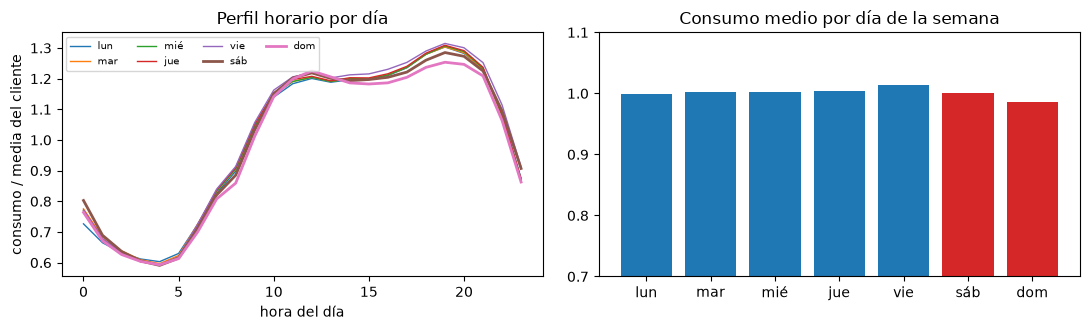

      0    1     2     3     4     5     6
4   0.6  0.6  0.59  0.59  0.59  0.59  0.59
12  1.2  1.2  1.20  1.21  1.22  1.22  1.23
19  1.3  1.3  1.31  1.31  1.31  1.29  1.25


In [6]:
pt_hol = holidays.Portugal(years=[2012, 2013, 2014])
rel = Y / Y.loc[:TRAIN_END].mean()
panel_rel = rel.mean(axis=1)                       # consumo relativo promedio del panel
days = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
prof = panel_rel.groupby([panel_rel.index.dayofweek, panel_rel.index.hour]).mean().unstack(0)
for d in range(7):
    ax[0].plot(prof.index, prof[d], label=days[d], lw=2 if d >= 5 else 1)
ax[0].set(xlabel="hora del día", ylabel="consumo / media del cliente", title="Perfil horario por día")
ax[0].legend(ncol=4, fontsize=7)
by_dow = panel_rel.groupby(panel_rel.index.dayofweek).mean()
ax[1].bar(days, by_dow, color=["C0"] * 5 + ["C3"] * 2)
ax[1].set(ylim=(0.7, 1.1), title="Consumo medio por día de la semana")
plt.tight_layout(); plt.savefig(FIGS / "perfiles.png", dpi=150); plt.show()
print(prof.round(2).loc[[4, 12, 19]])

### 2.2 Feriados de Portugal, Navidad y Año Nuevo

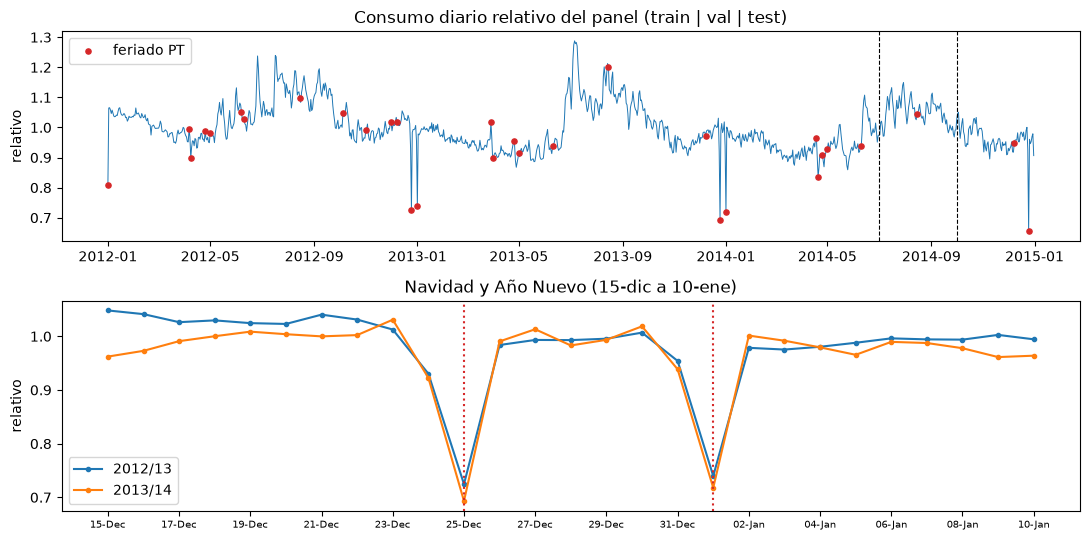

2012-12-24    0.919
2012-12-25    0.714
2012-12-31    0.966
2013-01-01    0.804
2013-12-24    0.939
2013-12-25    0.703
2013-12-31    0.969
2014-01-01    0.802
Name: ratio vs mismo día previo, dtype: float64
feriado (no fin de semana) vs mismo día previo: 0.951


In [7]:
daily = panel_rel.resample("D").mean()
hol_days = pd.DatetimeIndex([d for d in pt_hol if pd.Timestamp(d) in daily.index])
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5))
ax[0].plot(daily.index, daily, lw=0.7)
ax[0].scatter(hol_days, daily.loc[hol_days], color="C3", s=14, zorder=3, label="feriado PT")
for s in (VAL_START, TEST_START):
    ax[0].axvline(s, color="k", ls="--", lw=0.8)
ax[0].set(title="Consumo diario relativo del panel (train | val | test)", ylabel="relativo"); ax[0].legend()
for y0 in (2012, 2013):
    w = daily.loc[f"{y0}-12-15":f"{y0 + 1}-01-10"]
    ax[1].plot(np.arange(len(w)), w.values, marker=".", label=f"{y0}/{y0 + 1 - 2000:02d}")
ax[1].set_xticks(range(0, 27, 2), [f"{d:%d-%b}" for d in pd.date_range("2013-12-15", periods=27)[::2]], fontsize=7)
ax[1].axvline(10, color="C3", ls=":"); ax[1].axvline(17, color="C3", ls=":")
ax[1].set(title="Navidad y Año Nuevo (15-dic a 10-ene)", ylabel="relativo"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIGS / "feriados.png", dpi=150); plt.show()

def vs_same_weekday(day):
    """Consumo del día / media del mismo día de la semana en las 3 semanas previas."""
    d = pd.Timestamp(day)
    return daily.loc[d] / daily.loc[[d - pd.Timedelta(weeks=k) for k in (1, 2, 3)]].mean()

rows = {d: vs_same_weekday(d) for d in ["2012-12-24", "2012-12-25", "2012-12-31", "2013-01-01",
                                       "2013-12-24", "2013-12-25", "2013-12-31", "2014-01-01"]}
print(pd.Series(rows, name="ratio vs mismo día previo").round(3))
print("feriado (no fin de semana) vs mismo día previo:",
      round(np.mean([vs_same_weekday(d) for d in hol_days if d.dayofweek < 5 and d > pd.Timestamp("2012-01-22")]), 3))

### 2.3 Escalas entre clientes y normalización

In [8]:
means = Y.loc[:TRAIN_END].mean()
print(f"consumo medio por cliente (kWh/h): min {means.min():.2f} | mediana {means.median():.1f} "
      f"| max {means.max():,.0f} | max/min = {means.max() / means.min():,.0f}×")
print(means.describe().round(1).to_dict())

consumo medio por cliente (kWh/h): min 8.28 | mediana 150.0 | max 3,906 | max/min = 472×
{'count': 100.0, 'mean': 391.9, 'std': 677.3, 'min': 8.3, '25%': 71.6, '50%': 150.0, '75%': 333.5, 'max': 3905.8}


Las escalas difieren en varios órdenes de magnitud, así que una normalización **global** (un solo μ, σ) deja a los
clientes chicos en ≈0 y la pérdida la dominan los grandes. Se usa **z-score por serie con estadísticos de
entrenamiento** (μᵢ, σᵢ calculados solo hasta 2014-06-30): todas las series quedan comparables para un modelo global y
no se usa información futura. La normalización **por ventana** (RevIN) se evalúa como iteración en §5.2: adapta el
nivel a cada ventana y ayuda ante cambios de nivel, a cambio de perder el nivel absoluto de la serie. Las métricas
siempre se calculan después de invertir la transformación, en kWh.

In [9]:
def fit_scaler(Y_train, kind="series"):
    """Estadísticos SOLO del bloque de entrenamiento. kind='series': z-score por cliente; 'global': uno para todos."""
    if kind == "global":
        return np.full(Y_train.shape[1], Y_train.values.mean()), np.full(Y_train.shape[1], Y_train.values.std())
    return Y_train.mean().values, Y_train.std().values

MU, SD = fit_scaler(Y.loc[:TRAIN_END])
Z = ((Y.values - MU) / SD).astype(np.float32)          # (T, N) panel escalado
print("Z train: media", Z[:t_val].mean().round(3), "std", Z[:t_val].std().round(3),
      "| Z test: media", Z[t_test:].mean().round(3))

Z train: media 0.0 std 1.0 | Z test: media -0.107


### 2.4 Covariables de calendario (conocidas a futuro)

Hora, día de la semana y mes se codifican con **seno/coseno** (`sin(2πk/P)`, `cos(2πk/P)`): 2 columnas por ciclo en
vez de 24+7+12 one-hot, y la distancia entre 23:00 y 00:00 (o diciembre y enero) es la misma que entre horas
consecutivas. El feriado es binario (1 todo el día). Las 7 columnas dependen solo del reloj y del calendario oficial,
así que se conocen para cualquier hora futura al emitir el pronóstico.

In [10]:
def calendar(idx):
    hol = np.array([d in pt_hol for d in idx.date], dtype=np.float32)
    feats = {}
    for name, k, P in [("hour", idx.hour, 24), ("dow", idx.dayofweek, 7), ("month", idx.month - 1, 12)]:
        feats[f"{name}_sin"] = np.sin(2 * np.pi * k / P)
        feats[f"{name}_cos"] = np.cos(2 * np.pi * k / P)
    feats["holiday"] = hol
    return pd.DataFrame(feats, index=idx).astype(np.float32)

CAL = calendar(Y.index)
C = CAL.values                                          # (T, 7)
print(CAL.loc["2013-12-25 00:00":"2013-12-25 02:00"].round(3))

                     hour_sin  hour_cos  dow_sin  dow_cos  month_sin  \
2013-12-25 00:00:00     0.000     1.000    0.975   -0.223       -0.5   
2013-12-25 01:00:00     0.259     0.966    0.975   -0.223       -0.5   
2013-12-25 02:00:00     0.500     0.866    0.975   -0.223       -0.5   

                     month_cos  holiday  
2013-12-25 00:00:00      0.866      1.0  
2013-12-25 01:00:00      0.866      1.0  
2013-12-25 02:00:00      0.866      1.0  


### 2.5 Dataset de ventanas deslizantes

`WindowDataset` indexa pares (serie, inicio del objetivo `t0`). Para cada par:
- `X`: `(L, 1 + 7)` = y escalado en `[t0-L, t0)` + calendario de esas horas
- `y`: `(H,)` = y escalado en `[t0, t0+H)`
- `cal_f`: `(H, 7)` = calendario de las horas objetivo (para el decoder del seq2seq y la MLP)

Los splits se definen por la **fecha del objetivo**: una ventana es de validación si sus H horas objetivo caen en
validación (su entrada puede venir de train, que es pasado). `__getitems__` arma el batch completo con indexado
vectorizado de NumPy, mucho más rápido que llamar `__getitem__` 512 veces.

In [11]:
def target_starts(split, L=L, H=H, stride=1, months=None):
    """Índices t0 cuyo objetivo [t0, t0+H) cae completo dentro del split. months: historia de train a usar."""
    lo, hi = {"train": (0, t_val), "val": (t_val, t_test), "test": (t_test, T)}[split]
    if split == "train" and months:
        lo = Y.index.get_loc(VAL_START - pd.DateOffset(months=months))
    first = lo + L if split == "train" else lo        # en train la entrada también debe caer en la historia usada
    return np.arange(first, hi - H + 1, stride)


class WindowDataset(Dataset):
    """Ventanas deslizantes sobre todas las series del panel."""

    def __init__(self, Z, C, t0s, L=L, H=H, series=None):
        self.Z, self.C, self.t0s, self.L, self.H = Z, C, np.asarray(t0s), L, H
        self.series = np.arange(Z.shape[1]) if series is None else np.asarray(series)

    def __len__(self):
        return len(self.series) * len(self.t0s)

    def __getitems__(self, idx):
        idx = np.asarray(idx)
        n, t0 = self.series[idx // len(self.t0s)], self.t0s[idx % len(self.t0s)]
        past = t0[:, None] + np.arange(-self.L, 0)
        fut = t0[:, None] + np.arange(self.H)
        x = np.concatenate([self.Z[past, n[:, None]][..., None], self.C[past]], axis=-1)
        return (torch.from_numpy(x), torch.from_numpy(self.Z[fut, n[:, None]]),
                torch.from_numpy(self.C[fut]), torch.from_numpy(n))

    def __getitem__(self, i):
        return tuple(t[0] for t in self.__getitems__([i]))


def loader(ds, batch_size=512, shuffle=False, num_samples=None):
    """DataLoader que entrega el batch ya armado por __getitems__ (collate identidad)."""
    sampler = torch.utils.data.RandomSampler(ds, num_samples=num_samples) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, sampler=sampler, collate_fn=lambda b: b)


counts = {s: len(WindowDataset(Z, C, target_starts(s))) for s in ("train", "val", "test")}
print(pd.Series(counts, name=f"ventanas (L={L}, H={H}, stride 1 h, {N_CLIENTS} series)").map("{:,}".format))
print({s: f"{c // N_CLIENTS:,} por serie" for s, c in counts.items()})
x, y, cf, n = next(iter(loader(WindowDataset(Z, C, target_starts("train")), shuffle=True)))
print("X", tuple(x.shape), "| y", tuple(y.shape), "| cal_f", tuple(cf.shape), "| series", tuple(n.shape))

train    2,169,700
val        218,500
test       218,500
Name: ventanas (L=168, H=24, stride 1 h, 100 series), dtype: str
{'train': '21,697 por serie', 'val': '2,185 por serie', 'test': '2,185 por serie'}


X (512, 168, 8) | y (512, 24) | cal_f (512, 24, 7) | series (512,)


### 2.6 Auditoría de fugas

Regla: cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico (00:00 del día
objetivo, con datos hasta las 23:00 del día anterior). Las cuatro fugas vistas en clase y cómo las evita el pipeline:

In [12]:
times = Y.index
tr, va, te = (target_starts(s) for s in ("train", "val", "test"))

# 1) Split aleatorio de ventanas -> split cronológico por fecha del objetivo, sin solapes de objetivos
assert times[tr.max() + H - 1] <= TRAIN_END < times[va.min()]
assert times[va.max() + H - 1] <= VAL_END < times[te.min()]
rand = np.random.default_rng(0).permutation(np.r_[tr, va])[: len(va)]       # lo que haría un split aleatorio
print("1) split cronológico OK | con split aleatorio, % de 'val' con objetivo en train:",
      f"{(times[rand] <= TRAIN_END).mean():.0%}")

# 2) Escalar con toda la serie -> μ, σ solo de train; con la serie completa cambian (el futuro se filtra)
mu_all, sd_all = Y.mean().values, Y.std().values
assert np.allclose(MU, Y.loc[:TRAIN_END].mean().values)
print(f"2) scaler solo con train OK | |Δμ| medio si se usara toda la serie: {np.mean(np.abs(mu_all / MU - 1)):.1%}")

# 3) Early stopping con prueba -> los loaders de entrenamiento solo se construyen con 'train' y 'val';
#    train_model() (§5) verifica que la última hora objetivo de su loader de validación sea <= VAL_END
assert times[va.max() + H - 1] == VAL_END
print("3) validación termina en", VAL_END, "| prueba solo se toca dentro de backtest()")

# 4) Covariables mal alineadas -> X termina en t0-1 (dato real hasta 23:00); y y cal_f empiezan en t0
ds = WindowDataset(Z, C, te[::24])
x, y, cf, n = ds.__getitems__([0])
t0 = te[0]
assert times[t0] == TEST_START and times[t0 - 1].hour == 23
assert np.allclose(x[0, -1, 0], Z[t0 - 1, n[0]]) and np.allclose(y[0, 0], Z[t0, n[0]])
assert np.allclose(cf[0], calendar(times[t0:t0 + H]).values)          # calendario recalculado a futuro = cal_f
print("4) X:", times[t0 - L], "→", times[t0 - 1], "| y:", times[t0], "→", times[t0 + H - 1])

1) split cronológico OK | con split aleatorio, % de 'val' con objetivo en train: 91%
2) scaler solo con train OK | |Δμ| medio si se usara toda la serie: 1.1%
3) validación termina en 2014-09-30 23:00:00 | prueba solo se toca dentro de backtest()
4) X: 2014-09-24 00:00:00 → 2014-09-30 23:00:00 | y: 2014-10-01 00:00:00 → 2014-10-01 23:00:00
